# Diffusion models, part 2: generating the digit we ask for

In part 1 the model learned to draw handwritten digits, but it drew a **random** digit each time. Now we want to say "draw a 7" and get a 7. This is called **guiding** or **conditioning** the model. The same idea, with a text prompt in place of a digit label, is how text-to-image generators like Stable Diffusion work.

**Contents**

1. What we want, in terms of probabilities
2. Conditioning: give the label to the network
3. Training (same as part 1, plus the label)
4. Conditional sampling
5. Guidance: following the label more strongly
6. Classifier-free guidance in practice
7. From digits to text prompts

This notebook repeats the necessary code from part 1, so it runs on its own. Cells marked *(same as part 1)* need no new explanation.

In [1]:
# Cell 1: (same as part 1) Setup and imports
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import numpy as np
import keras
from keras import layers, ops
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

print(f"Keras version: {keras.__version__}")
print(f"Keras backend: {keras.config.backend()}")

I0000 00:00:1795255882.457088  107906 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795255882.488476  107906 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795255883.171857  107906 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras version: 3.15.1
Keras backend: tensorflow


In [2]:
# Cell 2: (same as part 1) Load MNIST, scale to [-1, 1] and pad to 32x32
(x_train, y_train), _ = keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 127.5 - 1.0                            # [0, 255] -> [-1, 1]
x_train = np.pad(x_train, ((0, 0), (2, 2), (2, 2)), constant_values=-1.0)  # 28x28 -> 32x32
x_train = x_train[..., None]                                                # add channel axis
y_train = y_train.astype("int32")

print(x_train.shape, x_train.min(), x_train.max())

NUM_CLASSES = 10
NULL_LABEL = NUM_CLASSES   # an extra label, 10, which means "no label" (see section 5)

(60000, 32, 32, 1) -1.0 1.0


In [3]:
# Cell 3: (same as part 1) Helpers for showing images
def to_img(x):
    # [-1, 1] -> [0, 1], drop the channel axis
    return np.clip((x[..., 0] + 1) / 2, 0, 1)

def show_grid(images, nrows, ncols, titles=None, figsize=None, suptitle=None):
    figsize = figsize or (ncols * 1.1, nrows * 1.1)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < len(images):
            ax.imshow(to_img(images[i]), cmap="gray", vmin=0, vmax=1)
            if titles is not None:
                ax.set_title(titles[i], fontsize=8)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

In [4]:
# Cell 4: (same as part 1) Noise schedule
T = 1000
betas = np.linspace(1e-4, 0.02, T).astype("float32")   # noise added at each step
alphas = 1.0 - betas
alpha_bars = np.cumprod(alphas).astype("float32")      # alpha_bar_t = alpha_1 * ... * alpha_t

def add_noise(x0, t, eps):
    # Jump straight to noise level t:  x_t = sqrt(alpha_bar_t) * x0 + sqrt(1 - alpha_bar_t) * eps
    a = alpha_bars[t].reshape(-1, 1, 1, 1)
    return np.sqrt(a) * x0 + np.sqrt(1.0 - a) * eps

## 1. What we want, in terms of probabilities

In part 1 the model learned to sample from $p(x)$, the distribution of all handwritten digits. Now we want to sample from the **conditional distribution** $p(x \mid y)$: the distribution of images *given* that the label is $y$. For example $p(x \mid y = 7)$ is the distribution of handwritten sevens.

There are two ways to get there, and both are used:

* **Conditioning:** train a model that gets $y$ as an extra input, so it learns $p(x\mid y)$ directly. (Sections 2–4.)
* **Guidance:** push the sampling process towards images that "look like a $y$", with an adjustable strength. (Sections 5–6.)

The modern standard, **classifier-free guidance**, combines the two, and it is surprisingly simple to implement.

## 2. Conditioning: give the label to the network

We give the network the label as a third input. The network becomes $\hat\varepsilon(x_t, t, y)$: "the noise in this image, at this noise level, *given that the image is a $y$*".

Knowing the label makes the denoising task easier, especially at high noise. In part 1, at $t = 700$ the network had to guess which digit is hiding in the noise. Now it is told.

**How the label enters the network.** The label is a category, not a quantity (7 is not "more" than 3), so we turn it into a vector with an **embedding layer**, as for words in a Transformer. Each label gets its own learned vector. This vector is concatenated with the time vector, and from there it follows the same route as the time information in part 1: in every residual block it is added to the feature maps. So every layer knows both *how noisy* the image is and *what it should become*.

**A practical detail we learned the hard way.** By default Keras initialises embedding vectors with very small values (between $-0.05$ and $0.05$), while the time features have values around $\pm1$. With such small label vectors the network first learns to ignore the label, and it can take a long time to start using it. Initialising the embeddings with standard deviation 1 puts the label on the same scale as the time from the start.

The label 10 means "no label". Section 5 explains why we need it.

In [5]:
# Cell 5: (same as part 1) Network building blocks
@keras.saving.register_keras_serializable()
class SinusoidalEmbedding(layers.Layer):
    # Turns the number t (shape (batch, 1)) into a vector of sines and cosines (shape (batch, dim))
    def __init__(self, dim, **kwargs):
        super().__init__(**kwargs)
        self.dim = dim

    def call(self, t):
        half = self.dim // 2
        freqs = ops.exp(-np.log(10000.0) * ops.arange(half, dtype="float32") / half)
        args = ops.cast(t, "float32") * freqs[None, :]
        return ops.concatenate([ops.sin(args), ops.cos(args)], axis=-1)

    def get_config(self):
        return {**super().get_config(), "dim": self.dim}


def res_block(x, emb, channels):
    # Residual block: two convolutions, plus the time information added to every pixel
    skip = x if x.shape[-1] == channels else layers.Conv2D(channels, 1)(x)
    h = layers.GroupNormalization(groups=8)(x)
    h = layers.Activation("swish")(h)
    h = layers.Conv2D(channels, 3, padding="same")(h)
    e = layers.Dense(channels)(emb)                 # one number per channel ...
    h = h + layers.Reshape((1, 1, channels))(e)     # ... added to every pixel of that channel
    h = layers.GroupNormalization(groups=8)(h)
    h = layers.Activation("swish")(h)
    h = layers.Conv2D(channels, 3, padding="same")(h)
    return layers.Add()([h, skip])


def unet_body(image_in, emb, widths):
    # Encoder 32 -> 16 -> 8 -> 4, bottleneck, decoder 4 -> 8 -> 16 -> 32 with skip connections
    x = layers.Conv2D(widths[0], 3, padding="same")(image_in)
    skips = []
    for w in widths:
        x = res_block(x, emb, w)
        skips.append(x)
        x = layers.Conv2D(w, 3, strides=2, padding="same")(x)      # downsample
    x = res_block(x, emb, widths[-1])
    x = res_block(x, emb, widths[-1])
    for w, s in zip(reversed(widths), reversed(skips)):
        x = layers.UpSampling2D(2)(x)                               # upsample
        x = layers.Concatenate()([x, s])                            # skip connection
        x = res_block(x, emb, w)
        x = res_block(x, emb, w)
    x = layers.GroupNormalization(groups=8)(x)
    x = layers.Activation("swish")(x)
    return layers.Conv2D(1, 3, padding="same", kernel_initializer="zeros")(x)

In [6]:
# Cell 6: The model: input (noisy image, t, label), output: predicted noise
def build_unet(widths=(32, 64, 128), emb_dim=128):
    image_in = keras.Input(shape=(32, 32, 1), name="noisy_image")
    t_in = keras.Input(shape=(1,), name="timestep")
    label_in = keras.Input(shape=(1,), dtype="int32", name="label")      # NEW

    t_emb = SinusoidalEmbedding(emb_dim)(t_in)
    t_emb = layers.Dense(emb_dim, activation="swish")(t_emb)

    # NEW: label embedding, on the same scale as the time features
    y_emb = layers.Embedding(NUM_CLASSES + 1, emb_dim,
                             embeddings_initializer=keras.initializers.RandomNormal(stddev=1.0))(label_in)
    y_emb = layers.Flatten()(y_emb)

    emb = layers.Concatenate()([t_emb, y_emb])                           # time + label together
    emb = layers.Dense(emb_dim, activation="swish")(emb)
    emb = layers.Dense(emb_dim, activation="swish")(emb)

    noise_out = unet_body(image_in, emb, widths)
    return keras.Model([image_in, t_in, label_in], noise_out, name="conditional_denoiser")

model = build_unet()
print(f"Parameters: {model.count_params():,}")

I0000 00:00:1795255884.397920  107906 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 751 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Ti, pci bus id: 0000:01:00.0, compute capability: 8.9


Parameters: 2,344,769


## 3. Training

Training is exactly as in part 1, with the label added to the input. There is one more change: in **10% of the examples we hide the label** by replacing it with 10 ("no label"). So the same network also learns the unconditional task of part 1. We'll need this in section 5.

In [7]:
# Cell 7: Training data generator
class NoisyBatches(keras.utils.PyDataset):
    def __init__(self, x, y, batch_size=128, p_uncond=0.1, seed=0, **kwargs):
        super().__init__(**kwargs)
        self.x, self.y = x, y
        self.batch_size = batch_size
        self.p_uncond = p_uncond
        self.rng = np.random.default_rng(seed)
        self.perm = self.rng.permutation(len(x))

    def __len__(self):
        return len(self.x) // self.batch_size

    def __getitem__(self, i):
        idx = self.perm[i * self.batch_size:(i + 1) * self.batch_size]
        x0 = self.x[idx]
        y = self.y[idx].copy()
        y[self.rng.random(len(y)) < self.p_uncond] = NULL_LABEL     # NEW: sometimes hide the label
        t = self.rng.integers(0, T, size=len(y))
        eps = self.rng.standard_normal(x0.shape).astype("float32")
        xt = add_noise(x0, t, eps)
        inputs = {"noisy_image": xt,
                  "timestep": t[:, None].astype("float32"),
                  "label": y[:, None]}                              # NEW
        return inputs, eps

    def on_epoch_end(self):
        self.perm = self.rng.permutation(len(self.x))

train_data = NoisyBatches(x_train, y_train)

Epoch 1/20


I0000 00:00:1795255884.979751  107906 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1795255893.591900  108445 service.cc:153] XLA service 0x794df4060330 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795255893.591916  108445 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Ti, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1795255893.872406  108445 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795255895.122924  108445 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1795255895.211834  108445 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_35891__.301
I0000 00:00:1795255895.592862  108445 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hint

  5/468 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - loss: 0.9746  

I0000 00:00:1795255909.587429  108445 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


468/468 ━━━━━━━━━━━━━━━━━━━━ 38s 29ms/step - loss: 0.0662
Epoch 2/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - loss: 0.0235
Epoch 3/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - loss: 0.0215
Epoch 4/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - loss: 0.0201
Epoch 5/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - loss: 0.0196
Epoch 6/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - loss: 0.0193
Epoch 7/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - loss: 0.0185
Epoch 8/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - loss: 0.0184
Epoch 9/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 14s 30ms/step - loss: 0.0183
Epoch 10/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 14s 30ms/step - loss: 0.0181
Epoch 11/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 14s 30ms/step - loss: 0.0178
Epoch 12/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 14s 30ms/step - loss: 0.0176
Epoch 13/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 14s 30ms/step - loss: 0.0177
Epoch 14/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 14s 30ms/step - loss: 0.0176
Epoch 15/20
468/468 ━━━━━━━━━━━━━━━━━━━━

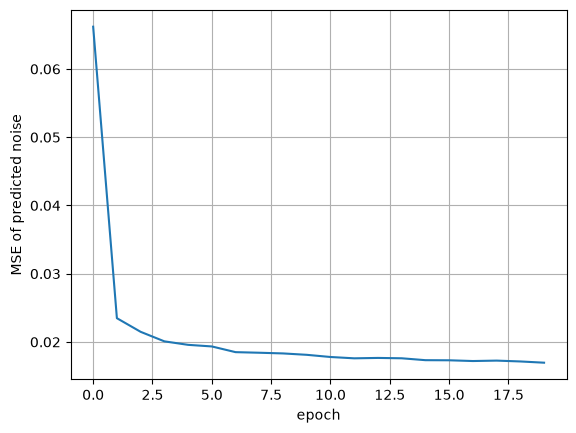

In [8]:
# Cell 8: Train
EPOCHS = 20   # check how long the first epoch takes, and reduce if needed

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3, use_ema=True, ema_momentum=0.99),
    loss="mse",
)
history = model.fit(train_data, epochs=EPOCHS)

plt.plot(history.history["loss"])
plt.xlabel("epoch"); plt.ylabel("MSE of predicted noise"); plt.grid(); plt.show()

model.save_weights("diffusion_mnist_conditional.weights.h5")

## 4. Conditional sampling

The sampler is the same as in part 1. The only difference is that every call to the network includes the label we want. The prediction function below also has a `guidance` parameter, which section 5 explains; with `guidance=1` it simply uses the conditional model.

In [9]:
# Cell 9: Prediction helpers (guidance is explained in section 5)
def predict_eps(x, t, labels, guidance=1.0):
    n = len(x)
    t_arr = np.full((n, 1), t, dtype="float32")
    cond = labels.reshape(-1, 1).astype("int32")
    uncond = np.full((n, 1), NULL_LABEL, dtype="int32")
    if guidance == 1.0:
        return model.predict_on_batch([x, t_arr, cond])          # conditional model only
    if guidance == 0.0:
        return model.predict_on_batch([x, t_arr, uncond])        # unconditional model only
    # Both predictions in one forward pass: stack the conditional and unconditional copies
    eps = model.predict_on_batch([np.concatenate([x, x]),
                                  np.concatenate([t_arr, t_arr]),
                                  np.concatenate([cond, uncond])])
    eps_cond, eps_uncond = eps[:n], eps[n:]
    return eps_uncond + guidance * (eps_cond - eps_uncond)

def predict_x0(x, t, eps):
    a = alpha_bars[t]
    return (x - np.sqrt(1 - a) * eps) / np.sqrt(a)

In [10]:
# Cell 10: The sampler (same as part 1, plus labels and guidance)
def sample(labels, guidance=1.0, seed=None, record_every=None):
    labels = np.asarray(labels)
    rng = np.random.default_rng(seed)
    x = rng.standard_normal((len(labels), 32, 32, 1)).astype("float32")
    frames = []
    for t in reversed(range(T)):
        eps = predict_eps(x, t, labels, guidance)
        x0 = np.clip(predict_x0(x, t, eps), -1, 1)
        a_bar, a_bar_prev = alpha_bars[t], (alpha_bars[t - 1] if t > 0 else 1.0)
        coef_x0 = np.sqrt(a_bar_prev) * betas[t] / (1 - a_bar)
        coef_xt = np.sqrt(alphas[t]) * (1 - a_bar_prev) / (1 - a_bar)
        x = coef_x0 * x0 + coef_xt * x
        if t > 0:
            sigma = np.sqrt((1 - a_bar_prev) / (1 - a_bar) * betas[t])
            x = x + sigma * rng.standard_normal(x.shape).astype("float32")
        if record_every and (t % record_every == 0 or t == T - 1):
            frames.append((t, x.copy(), x0.copy()))
    return (x, frames) if record_every else x

I0000 00:00:1795256188.631202  108441 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_68060__.47
I0000 00:00:1795256188.897061  108441 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


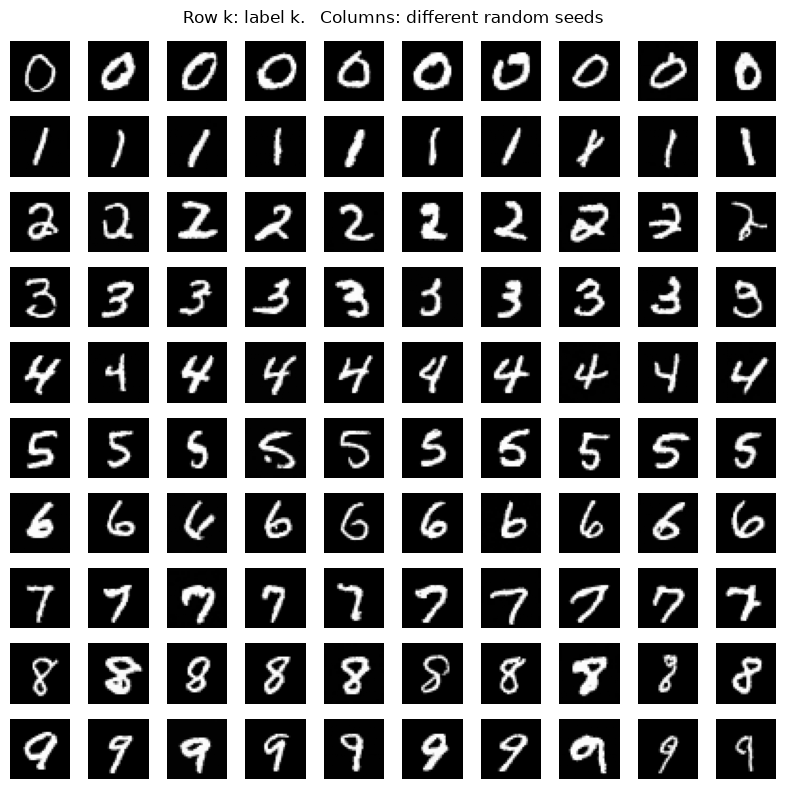

In [11]:
# Cell 11: Ten of each digit
labels = np.repeat(np.arange(10), 10)
samples = sample(labels, guidance=1.0, seed=42)
show_grid(samples, 10, 10, figsize=(8, 8), suptitle="Row k: label k.   Columns: different random seeds")

Each row should now contain one digit, written in different ways. The label decides **which** digit; the random noise decides **how** it is written (slant, thickness, style).

This answers a natural question: if the label is fixed, why don't we always get the same 7? Because the label only selects the distribution $p(x \mid y=7)$; the noise still picks a random sample from it.

Depending on how long the model was trained, some samples may be ugly or look like the wrong digit. Guidance fixes most of these.

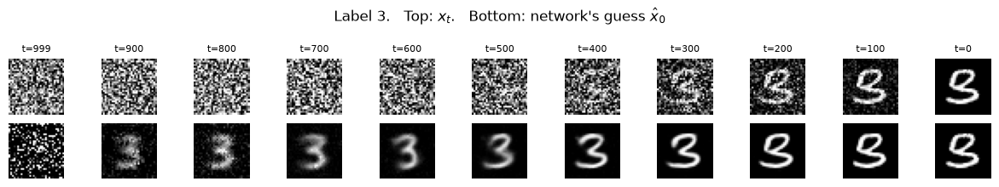

In [12]:
# Cell 12: Watching a 3 being generated: top x_t, bottom the network's guess x0_hat
_, frames = sample(np.array([3]), seed=7, record_every=1)
show_t = [999, 900, 800, 700, 600, 500, 400, 300, 200, 100, 0]
by_t = {t: (xt, x0) for t, xt, x0 in frames}
show_grid([by_t[t][0][0] for t in show_t] + [by_t[t][1][0] for t in show_t], 2, len(show_t),
          titles=[f"t={t}" for t in show_t] + [""] * len(show_t),
          suptitle=r"Label 3.   Top: $x_t$.   Bottom: network's guess $\hat x_0$")

Compare with part 1: there the early guesses were a blur of *all* digits. Now, already at high noise, the guess is a blurry **3**, because the network knows what it is looking for.

## 5. Guidance: following the label more strongly

### Classifier guidance: Bayes' formula for gradients

Recall from part 1 (section 8) that the noise predictor is essentially the **score**, the gradient of the log-density: $\hat\varepsilon \approx -\sqrt{1-\bar\alpha_t}\,\nabla \log p_t(x)$. For the conditional distribution we can use Bayes' formula,

$$
p(x \mid y) = \frac{p(y \mid x)\, p(x)}{p(y)} .
$$

Take logarithms and the gradient with respect to $x$. The term $p(y)$ does not depend on $x$, so it disappears:

$$
\nabla_x \log p(x \mid y) = \nabla_x \log p(x) + \nabla_x \log p(y \mid x).
$$

Read this as: *to move towards sevens, move towards more probable images in general, plus in the direction that makes a classifier more confident that the image is a 7.* Here $p(y\mid x)$ is a **classifier**, and its gradient with respect to the input image tells us how to change the image to make it look more like a $y$.

Dhariwal & Nichol (2021) used exactly this: an unconditional diffusion model plus a separately trained classifier. They also noticed that multiplying the classifier term by a factor $s > 1$ gives better-looking images,

$$
\nabla_x \log p(x) + s\,\nabla_x \log p(y \mid x),
$$

which corresponds to sampling from $p(x)\,p(y\mid x)^s$: images that are not only possible sevens, but *very clearly* sevens.

The drawback: the classifier must work on **noisy** images at every noise level, so it has to be trained specially, and it's an extra model to maintain.

### Classifier-free guidance: the classifier is hidden in the model

Ho & Salimans (2022) noticed that we don't need a separate classifier. Solve the Bayes equation above for the classifier term:

$$
\nabla_x \log p(y \mid x) = \nabla_x \log p(x\mid y) - \nabla_x \log p(x).
$$

The right side contains only the conditional and unconditional scores, and our network can give both: with the label $y$ it is the conditional model, and with label 10 ("no label") it is the unconditional one. **That is why 10% of the labels were hidden during training.**

Plugging this into the guided formula and translating scores back into noise predictions gives

$$
\boxed{\;\hat\varepsilon_{\text{guided}} = \hat\varepsilon(x_t, t, \varnothing) + s\,\big(\hat\varepsilon(x_t, t, y) - \hat\varepsilon(x_t, t, \varnothing)\big).\;}
$$

Start from the unconditional prediction, find the direction in which the label changes it, and go $s$ times that far.

* $s = 0$: the label is ignored and we get the unconditional model of part 1 (random digits).
* $s = 1$: the plain conditional model of section 4.
* $s > 1$: extrapolation beyond the conditional model. The images follow the label more strongly and look more "typical", but they also become more alike: we trade **variety** for **fidelity**.

The cost is two network evaluations per step instead of one (the code does both in the same batch). This is the method used in practically all modern image generators, and the `guidance_scale` setting in Stable Diffusion is exactly this $s$.

## 6. Classifier-free guidance in practice

Each panel below uses the **same random seeds**, so the only difference between panels is the guidance scale $s$. Columns are the labels $0, \dots, 9$.

I0000 00:00:1795256205.308483  108445 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_74242__.47


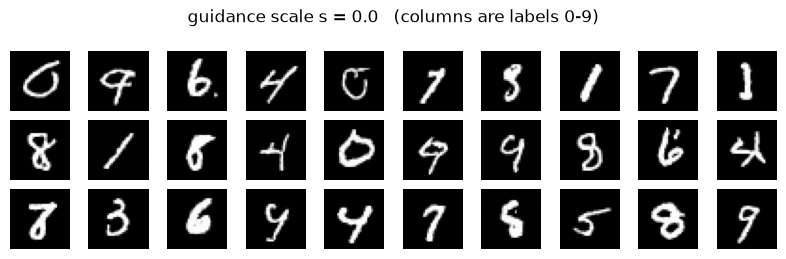

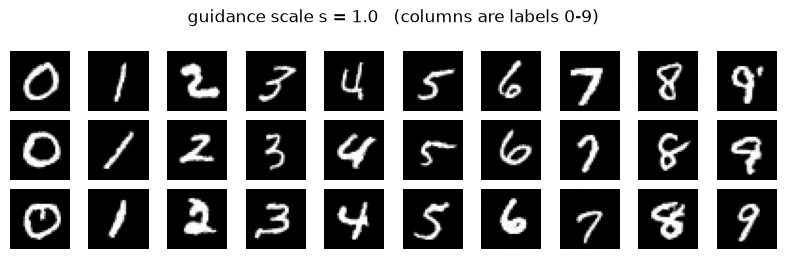

I0000 00:00:1795256214.030989  108445 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_74242__.47
I0000 00:00:1795256214.138449  108445 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1795256215.004517  108445 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1795256215.200431  108445 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


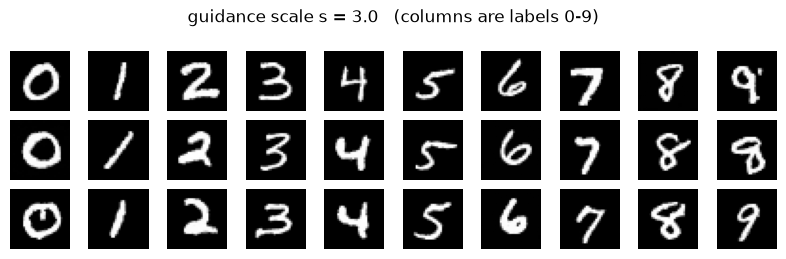

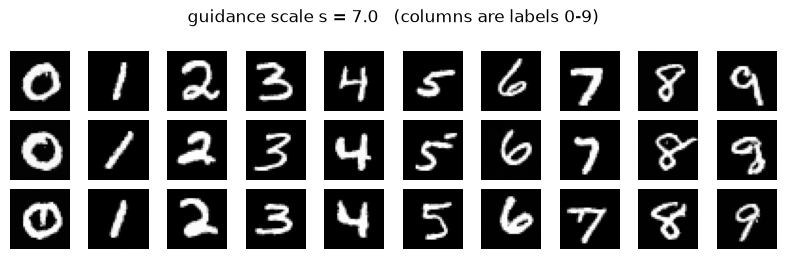

In [13]:
# Cell 13: Same seeds, different guidance scales
labels = np.tile(np.arange(10), 3)   # labels 0-9, three times
for s in [0.0, 1.0, 3.0, 7.0]:
    samples = sample(labels, guidance=s, seed=11)
    show_grid(samples, 3, 10, figsize=(8, 2.6), suptitle=f"guidance scale s = {s}   (columns are labels 0-9)")

What to look for:

* **$s = 0$:** random digits in every column, as in part 1. The label is not used at all.
* **$s = 1$:** mostly the right digits, but some are odd or ambiguous.
* **$s = 3$:** clear, well-formed digits of the right class.
* **$s = 7$:** very clean, thick, "textbook" digits. The three rows of a column look more alike than at $s = 1$. With very large $s$ the images eventually get distorted, because the extrapolation goes too far outside anything the model has seen.

In Stable Diffusion the typical default is around $s = 7$, for the same reason: a good balance between following the prompt and keeping variety and naturalness.

In [14]:
# Cell 14: Animation: digits 0-9 twice, generated with guidance 3
def tile(batch, ncols=8):
    imgs = to_img(batch)
    rows = [np.concatenate(list(imgs[i:i + ncols]), axis=1) for i in range(0, len(imgs), ncols)]
    return np.concatenate(rows, axis=0)

def animate(frames, ncols=8):
    fig, ax = plt.subplots(figsize=(ncols, 2.2 * len(frames[0][1]) / ncols / 2 + 0.4))
    ax.axis("off")
    im = ax.imshow(tile(frames[0][1], ncols), cmap="gray", vmin=0, vmax=1)
    title = ax.set_title("")
    def update(i):
        t, xt, _ = frames[i]
        im.set_data(tile(xt, ncols))
        title.set_text(f"t = {t}")
        return im, title
    anim = animation.FuncAnimation(fig, update, frames=len(frames), interval=80)
    plt.close(fig)
    return HTML(anim.to_jshtml())

labels = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9] * 2)
_, frames = sample(labels, guidance=3.0, seed=3, record_every=20)
animate(frames, ncols=10)

I0000 00:00:1795256226.394032  108441 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_74242__.47
I0000 00:00:1795256226.429828  108441 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1795256227.400628  108441 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1795256227.596858  108441 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


## 7. From digits to text prompts

Stable Diffusion and similar systems are this notebook with three changes:

1. **The label is replaced by a text prompt.** A pretrained text encoder (for example CLIP's) turns the prompt into a sequence of vectors, one per token. Instead of adding a single vector to the feature maps, the U-Net reads this sequence with **cross-attention** layers: each image position asks "which words of the prompt are relevant for me?". This is the attention mechanism from Transformers, with image features as queries and word vectors as keys and values.
2. **The diffusion runs in a compressed space.** An autoencoder first compresses $512\times512\times3$ images into $64\times64\times4$ *latents*, the diffusion model works on those, and the decoder turns the final latent into an image. This is called **latent diffusion**, and it makes everything far cheaper.
3. **Everything is much bigger**, and it is trained on hundreds of millions of image–caption pairs. During training, the caption is dropped some of the time, exactly like our 10% hidden labels, so that classifier-free guidance can be used.

The noise schedule, the training loss, the sampling loop and the guidance formula are the same as here.

### Questions and exercises

1. Set `p_uncond=0.0` in cell 7 and train again. What happens to guidance in cell 13, and why?
2. What happens with a very large guidance scale, such as $s = 20$?
3. Train on Fashion-MNIST (change `mnist` to `fashion_mnist` in cell 2). Labels are now clothing types.
4. Find the "average 3": in cell 12, look at the guess $\hat x_0$ at $t = 600$ or $700$. Compare it with the pixelwise average of all threes in the training data, `x_train[y_train == 3].mean(axis=0)`.
5. The label embedding is a learned vector for each digit. What do you think the network draws if you give it the *average* of the vectors for 1 and 7? (This needs a small change to the model: build a version that takes the embedding vector as input.)

References: Ho, Jain & Abbeel, *Denoising Diffusion Probabilistic Models* (2020). Dhariwal & Nichol, *Diffusion Models Beat GANs on Image Synthesis* (2021). Ho & Salimans, *Classifier-Free Diffusion Guidance* (2022). Rombach et al., *High-Resolution Image Synthesis with Latent Diffusion Models* (2022).